# Part 2: Question 1, Predicting GHG Intensity from Building Characteristics

**Data science project: Decarbonizing Chicago's Large Buildings**

**Name:** Bernard Issifu

**Question 1.** Which building characteristics best predict a building's GHG intensity?

This notebook uses the cleaned data from Part 1 (run `01_data_preparation_eda.ipynb` first). The R
version is `r/02_q1_regression.Rmd`.

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

bldg = pd.read_csv("../data/processed/buildings_latest_python.csv")
bldg["log_n_buildings"] = np.log(bldg["n_buildings"])
print(bldg.shape)

(3448, 24)


---
# 1. Approach

**Unit of analysis.** One row per building, its most recent report (3,448 buildings). Using every year
would put the same building in both the training and test sets, and its near-identical reports would
make the models look better than they are.

**Target.** `log(GHG intensity)`. GHG intensity is strongly right-skewed (Part 1), so the models predict
its logarithm; errors are reported on the log scale and, after converting back, in kg CO2e per sq ft.

**Features.** Only characteristics a city or retrofit company would know *without* the energy bills,
because GHG emissions are calculated directly from energy use and using it would make the problem
trivial:

- *property group* (10 categories, one-hot encoded with a dropped reference level);
- *log10 floor area*, *building age*, *log number of buildings*, *distance to downtown (km)*, *latitude*
  (north–south position) and the *data year* (standardized for the linear model).

**Models.** *Linear regression* (a transparent baseline; coefficients show direction and size of each
effect), a *regression tree* (depth 5, at least 30 buildings per leaf, for readable rules) and a
*random forest* (400 trees, at least 5 buildings per leaf, half of the features tried at each split),
which can capture interactions such as age mattering differently for schools and offices. A model using
*property group only* serves as a reference point.

**Evaluation.** 80/20 split stratified by property group, 5-fold cross-validation on the training set,
and test-set R², RMSE and MAE. Feature importance is measured by permutation (the drop in test R² when one
feature is shuffled) and by the linear coefficients.

In [2]:
num_cols = ["log_floor_area", "building_age", "log_n_buildings", "dist_downtown_km", "lat", "year"]
cat_cols = ["property_group"]
X = bldg[num_cols + cat_cols]
y = bldg["log_ghg_intensity"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,
                                                    stratify=bldg["property_group"])
print(f"Training: {len(X_train):,} buildings   Test: {len(X_test):,} buildings")

preprocess = ColumnTransformer([("num", StandardScaler(), num_cols),
                                ("cat", OneHotEncoder(drop="first"), cat_cols)])

Training: 2,758 buildings   Test: 690 buildings


---
# 2. Training and evaluation

In [3]:
models = {
    "Property group only": Pipeline([
        ("prep", ColumnTransformer([("cat", OneHotEncoder(drop="first"), cat_cols)])),
        ("model", LinearRegression())]),
    "Linear regression": Pipeline([("prep", preprocess), ("model", LinearRegression())]),
    "Regression tree": Pipeline([("prep", preprocess),
                                 ("model", DecisionTreeRegressor(max_depth=5, min_samples_leaf=30,
                                                                 random_state=42))]),
    "Random forest": Pipeline([("prep", preprocess),
                               ("model", RandomForestRegressor(n_estimators=400, min_samples_leaf=5,
                                                               max_features=0.5, n_jobs=2,
                                                               random_state=42))]),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows, preds = [], {}
for name, pipe in models.items():
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    preds[name] = p
    rows.append({"model": name,
                 "CV R² (mean ± sd)": f"{cv_r2.mean():.3f} ± {cv_r2.std():.3f}",
                 "Test R²": r2_score(y_test, p),
                 "Test RMSE (log)": mean_squared_error(y_test, p) ** 0.5,
                 "Test MAE (kg CO2e/sq ft)": mean_absolute_error(np.exp(y_test), np.exp(p)),
                 "Median abs. error (kg/sq ft)": np.median(np.abs(np.exp(y_test) - np.exp(p)))})

results = pd.DataFrame(rows).set_index("model").round(3)
results

,CV R² (mean ± sd),Test R²,Test RMSE (log),Test MAE (kg CO2e/sq ft),Median abs. error (kg/sq ft)
model,,,,,
Property group only,0.245 ± 0.028,0.276,0.418,2.256,1.394
Linear regression,0.245 ± 0.034,0.287,0.415,2.245,1.285
Regression tree,0.200 ± 0.019,0.223,0.433,2.380,1.398
Random forest,0.258 ± 0.031,0.312,0.408,2.246,1.380


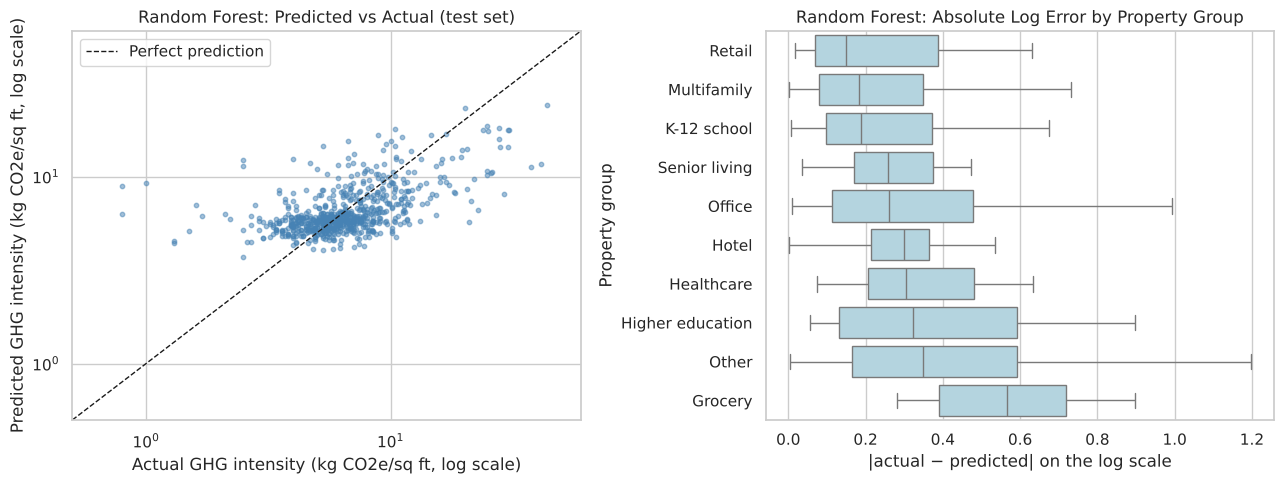

In [4]:
# Predicted vs actual GHG intensity on the test set (random forest)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
p_rf = preds["Random forest"]
axes[0].scatter(np.exp(y_test), np.exp(p_rf), s=10, alpha=0.5, color="steelblue")
lim = [0.5, 60]
axes[0].plot(lim, lim, "k--", lw=1, label="Perfect prediction")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_title("Random Forest: Predicted vs Actual (test set)")
axes[0].set_xlabel("Actual GHG intensity (kg CO2e/sq ft, log scale)")
axes[0].set_ylabel("Predicted GHG intensity (kg CO2e/sq ft, log scale)")
axes[0].legend()

resid = y_test - p_rf
by_group = pd.DataFrame({"group": X_test["property_group"], "abs_resid": np.abs(resid)})
order = by_group.groupby("group")["abs_resid"].median().sort_values().index
sns.boxplot(data=by_group, y="group", x="abs_resid", order=order, color="lightblue",
            showfliers=False, ax=axes[1])
axes[1].set_title("Random Forest: Absolute Log Error by Property Group")
axes[1].set_xlabel("|actual − predicted| on the log scale")
axes[1].set_ylabel("Property group")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_pred_vs_actual.png", dpi=150)
plt.show()

**Interpretation.** Building characteristics predict GHG intensity only weakly. The best model, the random forest, explains **31.2%** of the variance in log GHG intensity on the test set (cross-validated R² 0.258); linear regression reaches 0.287 and the regression tree 0.223. Strikingly, **property group alone explains 27.6%**, so age, size, location and year add only about 3–4 percentage points. In everyday units, the random forest's predictions are off by 2.25 kg CO2e/sq ft on average (median 1.38), against a median building of 6.2. The scatter plot shows the models pull predictions toward each group's typical value: they cannot tell an efficient office from a wasteful one.

---
# 3. Which characteristics matter?

## 3.1 Permutation importance (random forest)

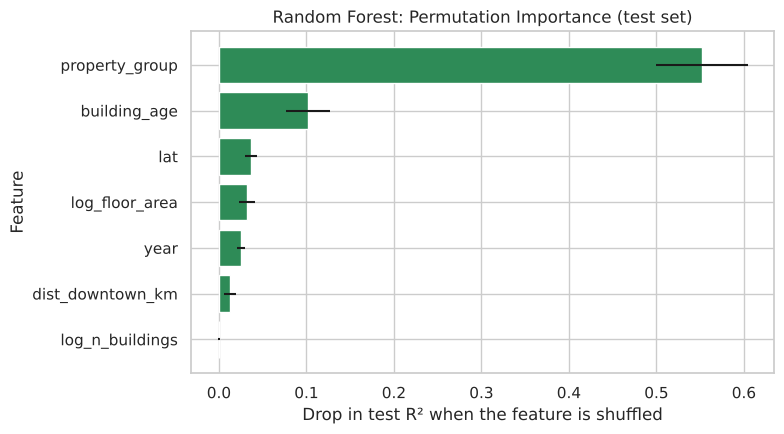

,mean_r2_drop,sd
property_group,0.5516,0.0525
building_age,0.1017,0.0249
lat,0.0363,0.0070
log_floor_area,0.0323,0.0094
year,0.0250,0.0044
dist_downtown_km,0.0128,0.0070
log_n_buildings,-0.0002,0.0014


In [5]:
rf = models["Random forest"]
perm = permutation_importance(rf, X_test, y_test, scoring="r2", n_repeats=10, random_state=42, n_jobs=2)
imp = (pd.DataFrame({"mean_r2_drop": perm.importances_mean, "sd": perm.importances_std},
                    index=X_test.columns).sort_values("mean_r2_drop", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index[::-1], imp["mean_r2_drop"][::-1], xerr=imp["sd"][::-1], color="seagreen")
ax.set_title("Random Forest: Permutation Importance (test set)")
ax.set_xlabel("Drop in test R² when the feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_permutation_importance.png", dpi=150)
plt.show()
imp.round(4)

## 3.2 Linear regression coefficients

In [6]:
lr = models["Linear regression"]
names = [n.replace("num__", "").replace("cat__property_group_", "type: ")
         for n in lr.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(lr.named_steps["model"].coef_, index=names)
# On the log scale, a coefficient b means GHG intensity changes by (exp(b) - 1) x 100%
effects = pd.DataFrame({"coefficient": coef, "pct_change_in_ghg": (np.exp(coef) - 1) * 100})
effects = effects.reindex(effects["coefficient"].abs().sort_values(ascending=False).index)
print("Reference property group: Grocery (alphabetically first)")
print("Numeric effects are per one standard deviation of the feature.")
effects.round(3)

Reference property group: Grocery (alphabetically first)
Numeric effects are per one standard deviation of the feature.


,coefficient,pct_change_in_ghg
type: Multifamily,-1.244,-71.177
type: K-12 school,-1.151,-68.365
type: Office,-1.015,-63.751
type: Retail,-0.903,-59.479
type: Senior living,-0.880,-58.510
type: Higher education,-0.823,-56.089
type: Hotel,-0.700,-50.335
type: Other,-0.595,-44.818
type: Healthcare,-0.179,-16.415
building_age,-0.040,-3.963


## 3.3 Regression tree: the top splits

In [7]:
tree = models["Regression tree"]
tree_names = [n.replace("num__", "").replace("cat__property_group_", "type_")
              for n in tree.named_steps["prep"].get_feature_names_out()]
print(export_text(tree.named_steps["model"], feature_names=tree_names, max_depth=2, decimals=2))

|--- type_Multifamily <= 0.50
|   |--- type_K-12 school <= 0.50
|   |   |--- type_Office <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- type_Office >  0.50
|   |   |   |--- truncated branch of depth 3
|   |--- type_K-12 school >  0.50
|   |   |--- building_age <= -0.07
|   |   |   |--- truncated branch of depth 3
|   |   |--- building_age >  -0.07
|   |   |   |--- truncated branch of depth 3
|--- type_Multifamily >  0.50
|   |--- building_age <= 1.01
|   |   |--- building_age <= -0.67
|   |   |   |--- truncated branch of depth 3
|   |   |--- building_age >  -0.67
|   |   |   |--- truncated branch of depth 3
|   |--- building_age >  1.01
|   |   |--- log_floor_area <= -0.67
|   |   |   |--- truncated branch of depth 3
|   |   |--- log_floor_area >  -0.67
|   |   |   |--- truncated branch of depth 3



The tree's thresholds are on the transformed scale (standardized numeric features; one-hot columns are
0/1), so `type_Multifamily <= 0.50` means "not multifamily".

In [8]:
results.to_csv(f"{FIG_DIR}/q1_results_python.csv")
imp.to_csv(f"{FIG_DIR}/q1_permutation_importance_python.csv")
effects.to_csv(f"{FIG_DIR}/q1_linear_effects_python.csv")

---
# 4. Discussion

**What predicts GHG intensity?** Property type, by a wide margin. Shuffling it lowers the random forest's
test R² by 0.55, five times more than any other feature, and in the linear model every group emits far
less per sq ft than grocery stores (the reference): multifamily buildings 71% less, K-12 schools 68%
less, offices 64% less, and healthcare only 16% less. Building age comes second in the random forest
(R² drop 0.10) but has a small, non-linear effect: within multifamily housing, buildings aged 25–74
(median 5.9–6.0 kg/sq ft) emit slightly more than newer ones (5.4) and the oldest, pre-1923 ones (4.9),
which may reflect mid-century construction with poor insulation, or older buildings having been
renovated. In the linear model each standard deviation of age (38 years) lowers intensity by only 4%.
Floor area, latitude, distance to downtown and data year each change predictions by 2% or less.

**What does this mean?** A building's type tells you what range of emissions to expect, but *where* a
building falls within that range depends on how it is operated and equipped (heating system, insulation,
controls, occupancy), none of which the city's records describe. Even the most flexible model leaves
about 70% of the variation unexplained. For decarbonization, this is a useful negative result: screening
buildings by their characteristics cannot replace measured energy data, and benchmarking programs like
Chicago's, which collect that data, are what make it possible to find the worst performers within each
building type. Part 3 uses the energy data directly to group buildings by how they use energy.

**Limitations.** One report per building, mostly 2023; self-reported data; and the property-type groups
merge some different uses into "Other".